# Conservation-law breaking at the edge of stability — reviewed multi-seed experiments

This notebook separates two questions:

1. **Theorem checks.** Given the rank-one central-flow covariance, do the
   derived conservation-law drifts hold?
2. **Approximation to discrete GD.** Once GD reaches the edge of stability
   (EOS), does the central-flow trajectory reproduce the slow drift of the
   gradient-flow conservation laws?

Every main experiment uses **three seeds**.  The code-review fixes incorporated
here are:

- headline GD centering uses the adjacent-iterate parameter midpoint
  \((\theta_k+\theta_{k+1})/2\), which exactly cancels a period-2 component;
- all scalar seeds have a non-vacuous stable-interpolator bound
  (\(\eta<1/y\)), and the scalar run is extended to \(T=200\) to report the
  observed saturation of that bound separately from the theorem;
- matrix-factorization seeds are restricted to runs where GD actually reaches
  EOS and the active trajectory remains safely rank one;
- the matrix instantaneous survival count is computed from the null space of
  the realized breaking functional;
- ReLU post-gate CF values are explicitly labelled **uncertified** with respect
  to the fixed-gate theorem.

Scalar and matrix factorization are globally smooth. ReLU is split into a
fixed-gate local theorem test and a trajectory stress test across gate changes.
For all trajectory experiments the initialization is below EOS.  The hybrid
central flow follows ordinary GF in the stable interior and switches to the
rank-one constrained field at the first EOS hit. A small projection back to
\(\lambda_1=2/\eta\) is used only as numerical constraint stabilization while
the constraint is active; it is not an additional continuous-time force.


In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import eigh, null_space
from scipy.integrate import solve_ivp

warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")
np.set_printoptions(precision=6, suppress=True)

RESULTS_DIR = Path.cwd() / "cf_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEEDS_SCALAR = [0, 1, 2]
# Seed 0 from the previous notebook never reached EOS under stable GD.
# We use three deterministic seeds for which the experiment's premise
# (GD reaches EOS while the hybrid-CF trajectory remains safely rank one) holds.
SEEDS_MF = [1, 3, 4]
SEEDS_RELU_LOCAL = [5, 7, 57]
SEEDS_RELU_TRAJ = [0, 1, 2]

# Scalar is cheap enough to run long enough to test the terminal stability bound.
T_SCALAR = 200
T_MF = 50
T_RELU = 80

# ReLU GF crosses kinks, so a fixed RK4 step has a visible conservation
# floor. We use high-accuracy adaptive DOP853 for the ReLU GF reference.
RELU_GF_RTOL = 1e-10
RELU_GF_ATOL = 1e-12
MF_RANK1_MAX_RATIO = 0.95

print("Results directory:", RESULTS_DIR)
print("Scalar seeds:", SEEDS_SCALAR)
print("Matrix-factorization seeds:", SEEDS_MF)
print("ReLU local-theorem seeds:", SEEDS_RELU_LOCAL)
print("ReLU trajectory seeds:", SEEDS_RELU_TRAJ)


Results directory: /Users/nelbo/Documents/PhD_work/code/CF_conserved_quantities/notebooks/cf_multiseed_results_fixed
Scalar seeds: [0, 1, 2]
Matrix-factorization seeds: [1, 3, 4]
ReLU local-theorem seeds: [5, 7, 57]
ReLU trajectory seeds: [0, 1, 2]


In [2]:

# ============================================================
# Shared numerical utilities
# ============================================================

def spectrum(model, theta):
    H = np.asarray(model["H"](theta), dtype=np.float64)
    vals, vecs = eigh(H)
    return vals.astype(np.float64), vecs.astype(np.float64)


def top_eig(model, theta):
    vals, vecs = spectrum(model, theta)
    return float(vals[-1]), vecs[:, -1], vals


def sharpness_grad(model, theta, q=None, eps=1e-6):
    """Hellmann--Feynman gradient of a simple top Hessian eigenvalue.

    q is frozen while differentiating q^T H(theta) q.
    """
    theta = np.asarray(theta, dtype=np.float64)
    if q is None:
        _, q, _ = top_eig(model, theta)

    q = np.asarray(q, dtype=np.float64)
    out = np.zeros_like(theta)

    for j in range(theta.size):
        e = np.zeros_like(theta)
        e[j] = eps
        hp = model["hvp"](theta + e, q)
        hm = model["hvp"](theta - e, q)
        out[j] = (q @ hp - q @ hm) / (2.0 * eps)

    return out


def relative_error(a, b, eps=1e-14):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    return np.linalg.norm(a - b) / (
        np.linalg.norm(a) + np.linalg.norm(b) + eps
    )


def midpoint_step(theta, dt, field):
    k1 = field(theta)
    mid = theta + 0.5 * dt * k1
    return theta + dt * field(mid)


def rk4_step(theta, dt, field):
    k1 = field(theta)
    k2 = field(theta + 0.5 * dt * k1)
    k3 = field(theta + 0.5 * dt * k2)
    k4 = field(theta + dt * k3)
    return theta + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


def integrate_gf(model, theta0, eta, t_end, dt=0.02, output_dt=1.0):
    """Accurate fixed-step RK4 GF in GD-step time: dtheta/dt = -eta grad L."""
    theta = np.asarray(theta0, dtype=np.float64).copy()
    times = np.arange(0.0, t_end + 0.5 * output_dt, output_dt)
    traj = [theta.copy()]

    field = lambda th: -eta * np.asarray(model["grad"](th), dtype=np.float64)

    for a, b in zip(times[:-1], times[1:]):
        width = float(b - a)
        n_sub = max(1, int(np.ceil(width / dt)))
        h = width / n_sub

        for _ in range(n_sub):
            theta = rk4_step(theta, h, field)

        traj.append(theta.copy())

    return times, np.asarray(traj)



def integrate_gf_adaptive(
    model,
    theta0,
    eta,
    t_end,
    output_dt=1.0,
    rtol=1e-10,
    atol=1e-12,
    max_step=0.05,
):
    """High-accuracy adaptive GF, useful for piecewise-smooth ReLU models.

    DOP853 adapts around activation-boundary crossings instead of losing
    fourth-order accuracy at a fixed RK4 step.
    """
    theta0 = np.asarray(theta0, dtype=np.float64)
    times = np.arange(0.0, t_end + 0.5 * output_dt, output_dt)

    def field(_t, th):
        return -eta * np.asarray(model["grad"](th), dtype=np.float64)

    sol = solve_ivp(
        field,
        (0.0, float(t_end)),
        theta0,
        t_eval=times,
        method="DOP853",
        rtol=rtol,
        atol=atol,
        max_step=max_step,
    )
    if not sol.success:
        raise RuntimeError(f"Adaptive GF integration failed: {sol.message}")

    return sol.t.astype(np.float64), sol.y.T.astype(np.float64)


def gradient_descent(model, theta0, eta, steps):
    theta = np.asarray(theta0, dtype=np.float64).copy()
    traj = [theta.copy()]

    for _ in range(int(steps)):
        theta = theta - eta * np.asarray(model["grad"](theta), dtype=np.float64)
        traj.append(theta.copy())

        if not np.all(np.isfinite(theta)):
            break

    return np.asarray(traj)


def boundary_record(model, theta, eta):
    """Rank-one constrained CF quantities at a point on/near lambda1=2/eta."""
    S, q, vals = top_eig(model, theta)
    g = np.asarray(model["grad"](theta), dtype=np.float64)
    gS = sharpness_grad(model, theta, q=q)

    denom = float(gS @ gS)
    dS_gf = float((-eta * g) @ gS)

    sigma2 = 0.0
    if dS_gf > 0.0 and denom > 1e-18:
        sigma2 = 2.0 * dS_gf / (eta * denom)

    v_cf = -eta * (g + 0.5 * sigma2 * gS)

    return {
        "S": S,
        "q": q,
        "eigvals": vals,
        "eigengap": float(vals[-1] - vals[-2]) if len(vals) > 1 else np.inf,
        "g": g,
        "gS": gS,
        "dS_gf": dS_gf,
        "sigma2": float(sigma2),
        "v_cf": v_cf,
        "dS_cf": float(v_cf @ gS),
    }


def project_to_sharpness(model, theta, critical, tol=1e-8, max_iter=5):
    """Numerical projection to lambda1(H)=critical along grad lambda1.

    This is constraint stabilization for the ODE solver, not an extra
    term in the continuous dynamics.
    """
    theta = np.asarray(theta, dtype=np.float64).copy()

    for _ in range(max_iter):
        S, q, _ = top_eig(model, theta)
        err = S - critical

        if abs(err) <= tol * max(1.0, abs(critical)):
            break

        gS = sharpness_grad(model, theta, q=q)
        denom = float(gS @ gS)

        if denom < 1e-18:
            break

        theta = theta - (err / denom) * gS

    return theta


def segment_hit(model, a, b, critical, n_bisect=35):
    """Locate the first lambda1=critical crossing along the segment [a,b]."""
    Sa = top_eig(model, a)[0]
    Sb = top_eig(model, b)[0]

    if Sa >= critical:
        return 0.0, project_to_sharpness(model, a, critical)

    if Sb < critical:
        return None, None

    lo, hi = 0.0, 1.0
    d = b - a

    for _ in range(n_bisect):
        alpha = 0.5 * (lo + hi)
        S = top_eig(model, a + alpha * d)[0]

        if S < critical:
            lo = alpha
        else:
            hi = alpha

    hit = a + hi * d
    hit = project_to_sharpness(model, hit, critical, tol=1e-10, max_iter=4)
    return hi, hit


def hybrid_cf_step(model, theta, eta, dt, hit_tol=1e-6):
    """One step of the hybrid GF -> rank-one constrained CF.

    - Below EOS: ordinary GF.
    - At EOS with dS_GF>0: rank-one constrained central flow.
    - If the constraint becomes inactive: ordinary GF may leave the boundary.

    Numerical projection is used only while the constraint is active.
    """
    critical = 2.0 / eta
    theta = np.asarray(theta, dtype=np.float64)

    def gf_field(th):
        return -eta * np.asarray(model["grad"](th), dtype=np.float64)

    S = top_eig(model, theta)[0]
    tol_abs = hit_tol * max(1.0, abs(critical))

    # Stable interior: follow GF until the first EOS hit.
    if S < critical - tol_abs:
        proposal = midpoint_step(theta, dt, gf_field)
        S_proposal = top_eig(model, proposal)[0]

        if S_proposal < critical:
            return proposal

        alpha, hit = segment_hit(model, theta, proposal, critical)
        remaining = dt * (1.0 - alpha)

        if remaining <= 1e-12:
            return hit

        return hybrid_cf_step(model, hit, eta, remaining, hit_tol=hit_tol)

    # We are numerically on/near the active boundary.
    theta = project_to_sharpness(model, theta, critical, tol=1e-9, max_iter=4)
    rec = boundary_record(model, theta, eta)

    # If GF would not increase sharpness, the constraint is inactive.
    if rec["sigma2"] <= 0.0:
        return midpoint_step(theta, dt, gf_field)

    # Projected midpoint step of the tangent constrained field.
    k1 = rec["v_cf"]
    mid = theta + 0.5 * dt * k1
    mid = project_to_sharpness(model, mid, critical, tol=1e-7, max_iter=2)

    rec_mid = boundary_record(model, mid, eta)
    k2 = rec_mid["v_cf"] if rec_mid["sigma2"] > 0.0 else gf_field(mid)

    new = theta + dt * k2

    # If the active constraint remains binding, remove numerical normal drift.
    rec_new = boundary_record(model, new, eta)
    if rec_new["sigma2"] > 0.0:
        new = project_to_sharpness(model, new, critical, tol=1e-8, max_iter=4)

    return new


def integrate_hybrid_cf(model, theta0, eta, t_end, dt=0.1, output_dt=1.0):
    theta = np.asarray(theta0, dtype=np.float64).copy()
    times = np.arange(0.0, t_end + 0.5 * output_dt, output_dt)
    traj = [theta.copy()]

    for a, b in zip(times[:-1], times[1:]):
        width = float(b - a)
        n_sub = max(1, int(np.ceil(width / dt)))
        h = width / n_sub

        for _ in range(n_sub):
            theta = hybrid_cf_step(model, theta, eta, h)

        traj.append(theta.copy())

    return times, np.asarray(traj)


def find_gf_eos_hit(model, theta0, eta, max_time=50.0, dt=0.02):
    """First EOS point on the GF trajectory, refined along the crossing segment."""
    critical = 2.0 / eta
    theta = np.asarray(theta0, dtype=np.float64).copy()
    t = 0.0

    gf_field = lambda th: -eta * np.asarray(model["grad"](th), dtype=np.float64)

    if top_eig(model, theta)[0] >= critical:
        return 0.0, project_to_sharpness(model, theta, critical)

    while t < max_time:
        proposal = midpoint_step(theta, dt, gf_field)

        if top_eig(model, proposal)[0] >= critical:
            alpha, hit = segment_hit(model, theta, proposal, critical)
            return t + alpha * dt, hit

        theta = proposal
        t += dt

    raise RuntimeError("GF did not hit EOS in the requested time window.")


def moving_parameter_center(traj, window=5):
    """Generic symmetric parameter moving average (diagnostic only).

    WARNING: an odd boxcar window does not exactly remove a period-2 EOS
    oscillation (a 5-point average leaks exactly 1/5 of its amplitude).
    The headline GD-center curves therefore use adjacent_midpoint below.
    Endpoint windows are truncated and consequently biased.
    """
    traj = np.asarray(traj, dtype=np.float64)

    if window % 2 == 0:
        raise ValueError("window must be odd")

    half = window // 2
    out = np.empty_like(traj)

    for k in range(len(traj)):
        lo = max(0, k - half)
        hi = min(len(traj), k + half + 1)
        out[k] = traj[lo:hi].mean(axis=0)

    return out


def adjacent_midpoint(traj):
    """Parameter midpoint (theta_k + theta_{k+1})/2 at time k+1/2.

    This cancels an exact period-2 component +delta,-delta.
    Conservation laws are evaluated after averaging parameters.
    """
    traj = np.asarray(traj, dtype=np.float64)
    if len(traj) < 2:
        raise ValueError("adjacent_midpoint needs at least two iterates")
    return 0.5 * (traj[:-1] + traj[1:])


def midpoint_times(n_iterates):
    return np.arange(n_iterates - 1, dtype=np.float64) + 0.5


def interpolate_vector_values(t_query, t_source, values):
    """Linear interpolation of a scalar/vector trajectory along its first axis."""
    t_query = np.asarray(t_query, dtype=np.float64)
    t_source = np.asarray(t_source, dtype=np.float64)
    values = np.asarray(values, dtype=np.float64)

    if values.ndim == 1:
        return np.interp(t_query, t_source, values)

    return np.column_stack([
        np.interp(t_query, t_source, values[:, j])
        for j in range(values.shape[1])
    ])


def law_displacement(values, initial=None, eps=1e-12):
    """Relative displacement from the ORIGINAL GF-law value.

    We assert a non-negligible initial norm instead of silently dividing by
    an arbitrary epsilon, which would make near-balanced initializations
    appear to have enormous relative violations.
    """
    values = np.asarray(values, dtype=np.float64)
    if values.ndim == 1:
        values = values[:, None]

    if initial is None:
        initial = values[0]

    initial = np.asarray(initial, dtype=np.float64)
    if initial.ndim == 0:
        initial = initial.reshape(1)

    scale = float(np.linalg.norm(initial))
    if not np.isfinite(scale) or scale <= eps:
        raise ValueError(
            f"Initial conservation-law norm {scale:.3e} is too small for "
            "a meaningful relative-displacement normalization."
        )

    return np.linalg.norm(values - initial[None, :], axis=1) / scale


def choose_eta_from_gf_pilot(model, theta0, fraction=0.5, pilot_time=20.0):
    """Choose 2/eta strictly between initial and reachable GF sharpness.

    The pilot uses eta=1 only to identify a reachable point on the same
    gradient-flow path (eta changes only the GF time parametrization).
    """
    _, pilot = integrate_gf(model, theta0, eta=1.0, t_end=pilot_time,
                            dt=0.05, output_dt=0.5)

    sharp = np.asarray([top_eig(model, th)[0] for th in pilot])
    S0 = float(sharp[0])
    Smax = float(sharp.max())

    if Smax <= 1.01 * S0:
        raise RuntimeError(
            f"Pilot GF did not increase sharpness enough: S0={S0:.4f}, Smax={Smax:.4f}"
        )

    critical = S0 + fraction * (Smax - S0)
    eta = 2.0 / critical

    return eta, S0, Smax, critical


def mean_std(curves):
    curves = np.asarray(curves, dtype=np.float64)
    return curves.mean(axis=0), curves.std(axis=0)


def first_index(mask):
    idx = np.where(np.asarray(mask))[0]
    return int(idx[0]) if len(idx) else None


In [3]:

# ============================================================
# Models and conservation-law / breaking-matrix helpers
# ============================================================

def make_scalar(y=1.0):
    y = float(y)

    def loss(t):
        u, v = np.asarray(t, dtype=np.float64)
        return 0.5 * (u * v - y) ** 2

    def grad(t):
        u, v = np.asarray(t, dtype=np.float64)
        rho = u * v - y
        return np.array([rho * v, rho * u], dtype=np.float64)

    def H(t):
        u, v = np.asarray(t, dtype=np.float64)
        b = 2.0 * u * v - y
        return np.array([[v * v, b], [b, u * u]], dtype=np.float64)

    def hvp(t, d):
        return H(t) @ np.asarray(d, dtype=np.float64)

    def h(t):
        u, v = np.asarray(t, dtype=np.float64)
        return float(u * u - v * v)

    def h_grad(t):
        u, v = np.asarray(t, dtype=np.float64)
        return np.array([2.0 * u, -2.0 * v], dtype=np.float64)

    return {
        "loss": loss, "grad": grad, "H": H, "hvp": hvp,
        "h": h, "h_grad": h_grad, "y": y,
    }


def make_matfact(n, m, r, Y):
    Y = np.asarray(Y, dtype=np.float64)
    dU = n * r

    def unpack(t):
        t = np.asarray(t, dtype=np.float64)
        return t[:dU].reshape(n, r), t[dU:].reshape(m, r)

    def pack(U, V):
        return np.concatenate([U.ravel(), V.ravel()]).astype(np.float64)

    def loss(t):
        U, V = unpack(t)
        G = U @ V.T - Y
        return 0.5 * np.sum(G * G)

    def grad(t):
        U, V = unpack(t)
        G = U @ V.T - Y
        return pack(G @ V, G.T @ U)

    def hvp(t, d):
        U, V = unpack(t)
        dU, dV = unpack(d)
        G = U @ V.T - Y
        dG = dU @ V.T + U @ dV.T
        return pack(dG @ V + G @ dV, dG.T @ U + G.T @ dU)

    def H(t):
        D = len(t)
        eye = np.eye(D)
        Hm = np.column_stack([hvp(t, eye[:, j]) for j in range(D)])
        return 0.5 * (Hm + Hm.T)

    def psi(t):
        U, V = unpack(t)
        return U.T @ U - V.T @ V

    def psi_dot(t, velocity):
        U, V = unpack(t)
        dU, dV = unpack(velocity)
        return dU.T @ U + U.T @ dU - dV.T @ V - V.T @ dV

    def breaking_rank1(t, q, sigma2):
        U, V = unpack(t)
        qU, qV = unpack(q)

        PU = U.T @ U
        PV = V.T @ V
        RU = sigma2 * (qU.T @ qU)
        RV = sigma2 * (qV.T @ qV)

        N = sigma2 * ((qV.T @ V) @ (qU.T @ U))
        Np = sigma2 * ((qU.T @ U) @ (qV.T @ V))

        Btil = (
            PU @ RV + RV @ PU
            - PV @ RU - RU @ PV
            + 2.0 * (N - Np)
        )
        Bcal = 0.5 * (Btil + Btil.T)

        return Btil, Bcal

    return {
        "loss": loss, "grad": grad, "H": H, "hvp": hvp,
        "unpack": unpack, "pack": pack, "psi": psi, "psi_dot": psi_dot,
        "breaking_rank1": breaking_rank1, "r": r,
    }


def sym2_coords(M):
    """Frobenius-orthonormal coordinates for Sym(2)."""
    M = np.asarray(M, dtype=np.float64)
    return np.array([M[0, 0], M[1, 1], np.sqrt(2.0) * M[0, 1]])


def make_relu(n_in, r, X, y):
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    N = X.shape[0]

    def unpack(t):
        t = np.asarray(t, dtype=np.float64)
        U = t[:r].reshape(1, r)
        V = t[r:].reshape(n_in, r)
        return U, V

    def pack(U, V):
        return np.concatenate([U.ravel(), V.ravel()]).astype(np.float64)

    def forward(t):
        U, V = unpack(t)
        Z = X @ V
        A = np.maximum(Z, 0.0)
        pred = (A @ U.T).ravel()
        return pred, Z, A, U, V

    def loss(t):
        pred, _, _, _, _ = forward(t)
        return 0.5 * np.mean((pred - y) ** 2)

    def grad(t):
        pred, Z, A, U, V = forward(t)
        res = (pred - y) / N
        mask = (Z > 0.0).astype(np.float64)

        gU = (res @ A).reshape(1, r)
        gV = X.T @ (np.outer(res, U.ravel()) * mask)

        return pack(gU, gV)

    def hvp(t, d):
        # Exact piecewise Hessian while the activation mask is fixed.
        pred, Z, A, U, V = forward(t)
        dU, dV = unpack(d)

        mask = (Z > 0.0).astype(np.float64)
        res = (pred - y) / N

        dA = mask * (X @ dV)
        dpred = (dA @ U.T).ravel() + (A @ dU.T).ravel()
        dres = dpred / N

        dgU = (dres @ A + res @ dA).reshape(1, r)
        dterm = (
            np.outer(dres, U.ravel()) * mask
            + np.outer(res, dU.ravel()) * mask
        )
        dgV = X.T @ dterm

        return pack(dgU, dgV)

    def H(t):
        D = len(t)
        eye = np.eye(D)
        Hm = np.column_stack([hvp(t, eye[:, j]) for j in range(D)])
        return 0.5 * (Hm + Hm.T)

    def hvec(t):
        U, V = unpack(t)
        return U.ravel() ** 2 - np.sum(V * V, axis=0)

    def hdot(t, velocity):
        U, V = unpack(t)
        dU, dV = unpack(velocity)
        return (
            2.0 * U.ravel() * dU.ravel()
            - 2.0 * np.sum(V * dV, axis=0)
        )

    def breaking_rank1(t, q, sigma2):
        pred, Z, Aact, U, V = forward(t)
        qU, qV = unpack(q)

        PU = U.T @ U
        RU = sigma2 * (qU.T @ qU)

        # Loss uses a dataset mean, so all data contractions are means.
        Pi = np.zeros((r, r), dtype=np.float64)
        Rgate = np.zeros((r, r), dtype=np.float64)
        Ne = np.zeros((r, r), dtype=np.float64)
        Nep = np.zeros((r, r), dtype=np.float64)

        K = qU.T @ U

        for i in range(N):
            mask_i = (Z[i] > 0.0).astype(np.float64)
            pi = Aact[i]
            alpha_q = mask_i * (qV.T @ X[i])

            Pi += np.outer(pi, pi) / N
            Rgate += sigma2 * np.outer(alpha_q, alpha_q) / N
            Ne += sigma2 * (np.outer(alpha_q, pi) @ K) / N
            Nep += sigma2 * (K @ np.outer(alpha_q, pi)) / N

        Btil = (
            PU @ Rgate + Rgate @ PU
            - Pi @ RU - RU @ Pi
            + 2.0 * (Ne - Nep)
        )

        return Btil

    def gate_safety_rank1(t, q, sigma2):
        _, Z, _, _, _ = forward(t)
        _, qV = unpack(q)

        if sigma2 <= 0.0:
            return {"safe": True, "ratio": np.inf, "Z": Z, "dz": np.zeros_like(Z)}

        dz = np.sqrt(sigma2) * (X @ qV)

        base = Z > 0.0
        plus = (Z + dz) > 0.0
        minus = (Z - dz) > 0.0

        safe = bool(
            np.array_equal(base, plus)
            and np.array_equal(base, minus)
        )
        ratio = float(np.min(np.abs(Z) / (np.abs(dz) + 1e-15)))

        return {"safe": safe, "ratio": ratio, "Z": Z, "dz": dz}

    return {
        "loss": loss, "grad": grad, "H": H, "hvp": hvp,
        "unpack": unpack, "pack": pack, "forward": forward,
        "hvec": hvec, "hdot": hdot,
        "breaking_rank1": breaking_rank1,
        "gate_safety_rank1": gate_safety_rank1,
        "r": r, "X": X,
    }


In [4]:

# ============================================================
# Deterministic multi-seed setups
# ============================================================

def setup_scalar(seed):
    rng = np.random.default_rng(seed)
    model = make_scalar(y=1.0)

    u0 = 1.0 + 0.45 * rng.random()
    v0 = 0.05 + 0.25 * rng.random()
    theta0 = np.array([u0, v0], dtype=np.float64)

    S0 = top_eig(model, theta0)[0]
    h0 = model["h"](theta0)

    # Along scalar GF, h is fixed, so the interpolating sharpness is known.
    S_star = np.sqrt(h0 ** 2 + 4.0 * model["y"] ** 2)

    # Base threshold used in the previous notebook.
    critical_base = 0.55 * S0 + 0.45 * S_star

    # The stable solution-manifold bound
    # |h_inf| <= 2 sqrt(eta^{-2} - y^2)
    # is meaningful only when eta < 1/y, equivalently 2/eta > 2y.
    # Enforce this while keeping S0 < critical < S_star.
    critical_stable = (
        2.0 * model["y"]
        + 0.25 * (S_star - 2.0 * model["y"])
    )
    critical = max(critical_base, critical_stable)
    eta = 2.0 / critical

    assert S0 < critical < S_star
    assert critical > 2.0 * model["y"]
    assert eta < 1.0 / model["y"]

    return model, theta0, eta, {
        "seed": seed,
        "S0": S0,
        "Smax_GF": S_star,
        "critical": critical,
    }


def setup_mf(seed):
    rng = np.random.default_rng(seed)

    n = m = 3
    r = 2

    # Exact rank-2 target: genuine factorization/interpolation.
    Y_left = rng.standard_normal((n, r))
    Y_right = rng.standard_normal((m, r))
    Y = Y_left @ Y_right.T

    model = make_matfact(n, m, r, Y)

    U0 = 0.8 * rng.standard_normal((n, r))
    V0 = 0.3 * rng.standard_normal((m, r))
    theta0 = model["pack"](U0, V0)

    eta, S0, Smax, critical = choose_eta_from_gf_pilot(
        model, theta0, fraction=0.5, pilot_time=15.0
    )

    return model, theta0, eta, {
        "seed": seed,
        "S0": S0,
        "Smax_GF": Smax,
        "critical": critical,
    }


def setup_relu(seed):
    """Original-style unnormalized Gaussian teacher-student ReLU setup."""
    rng = np.random.default_rng(seed)

    n_in = 4
    r = 3
    N = 24

    X = rng.standard_normal((N, n_in))
    w_teacher = rng.standard_normal(n_in)
    y = X @ w_teacher

    model = make_relu(n_in, r, X, y)

    U0 = 0.6 * rng.standard_normal((1, r))
    V0 = 0.25 * rng.standard_normal((n_in, r))
    theta0 = model["pack"](U0, V0)

    eta, S0, Smax, critical = choose_eta_from_gf_pilot(
        model, theta0, fraction=0.5, pilot_time=20.0
    )

    return model, theta0, eta, {
        "seed": seed,
        "S0": S0,
        "Smax_GF": Smax,
        "critical": critical,
    }


def active_cf_diagnostics(model, traj, eta):
    """Diagnostics only at sampled points close to an active EOS boundary."""
    critical = 2.0 / eta

    lambda1 = []
    lambda2 = []
    sigma2 = []
    gap = []

    for th in traj:
        vals, _ = spectrum(model, th)
        lambda1.append(vals[-1])
        lambda2.append(vals[-2] if len(vals) > 1 else np.nan)
        gap.append(vals[-1] - vals[-2] if len(vals) > 1 else np.inf)

        if abs(vals[-1] - critical) <= 2e-3 * max(1.0, abs(critical)):
            rec = boundary_record(model, th, eta)
            sigma2.append(rec["sigma2"])
        else:
            sigma2.append(0.0)

    return {
        "lambda1": np.asarray(lambda1),
        "lambda2": np.asarray(lambda2),
        "sigma2": np.asarray(sigma2),
        "eigengap": np.asarray(gap),
    }


## 1. Scalar factorization — three seeds

For each seed we start below EOS and choose \(2/\eta\) between the initial
sharpness and the sharpness of the GF interpolator, with the additional
constraint \(2/\eta>2y\) so the stable solution-manifold bound is non-vacuous.
We test

\[
h=u^2-v^2,\qquad
\dot h
=
-\frac{\eta\sigma^2}{2}
h\left(2+\frac{u^2+v^2}{R}\right)
\]

at the first GF hitting point of EOS.  The trajectory comparison uses the
adjacent-iterate **parameter midpoint** for GD, which exactly removes a
period-2 component.  We integrate hybrid
CF to \(T=200\) and separately report whether its terminal value empirically
saturates the rigorous stability bound; saturation is an observation, not
assumed by the theorem.


,seed,eta,EOS hit time (GF),pointwise relative error,h(0),h_CF(T=200),|h_CF(T)| stability bound,|h_CF(T)| / bound,h_GD-mid(end),GF max law drift,max active-CF |lambda1/(2/eta)-1|
0,0,0.902559,0.878622,5.906964e-11,1.641630,0.954100,0.954100,1.0,0.370256,8.535730e-09,5.819867e-09
1,1,0.945716,0.799776,8.136571e-11,1.430964,0.687297,0.687297,1.0,0.429902,4.856107e-09,3.348885e-09
2,2,0.958091,1.243603,7.793386e-11,1.233779,0.597990,0.597990,1.0,0.275364,5.235985e-09,2.211549e-09


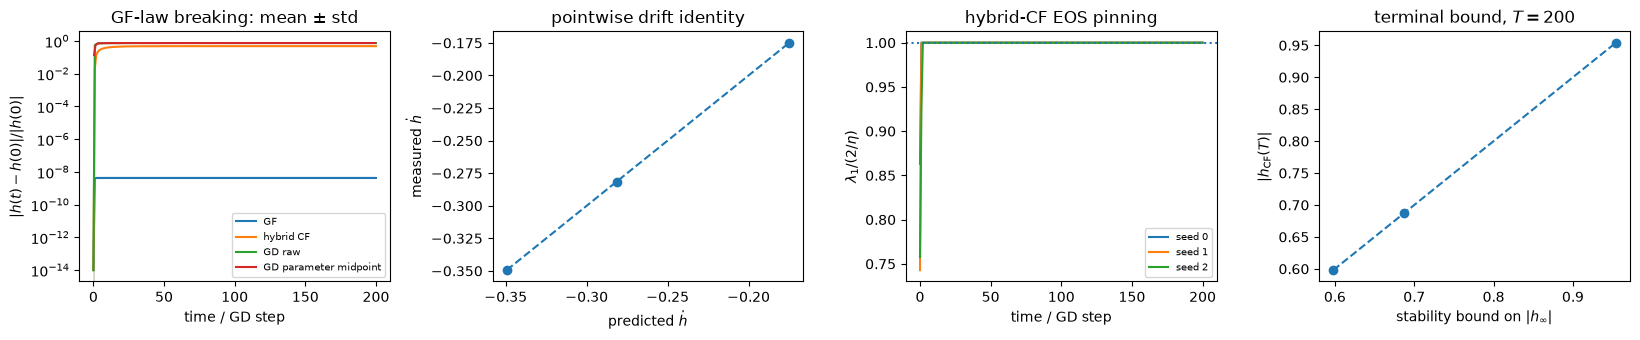

In [5]:
SCALAR_RUNS = []
scalar_rows = []

for seed in SEEDS_SCALAR:
    model, theta0, eta, setup = setup_scalar(seed)
    critical = 2.0 / eta

    # Full trajectories from the same pre-EOS initialization.
    t_gf, gf = integrate_gf(
        model, theta0, eta, T_SCALAR, dt=0.02, output_dt=1.0
    )
    t_cf, cf = integrate_hybrid_cf(
        model, theta0, eta, T_SCALAR, dt=0.02, output_dt=1.0
    )
    gd = gradient_descent(model, theta0, eta, T_SCALAR)

    # Exact period-2 parameter center.
    gd_mid = adjacent_midpoint(gd)
    t_mid = midpoint_times(len(gd))

    h_gf = np.asarray([model["h"](th) for th in gf])
    h_cf = np.asarray([model["h"](th) for th in cf])
    h_gd = np.asarray([model["h"](th) for th in gd])
    h_mid = np.asarray([model["h"](th) for th in gd_mid])

    h0 = float(h_gf[0])
    assert abs(h0) > 1e-8

    # Exact pointwise theorem check at the first GF EOS hit.
    t_hit, theta_hit = find_gf_eos_hit(model, theta0, eta)
    rec = boundary_record(model, theta_hit, eta)

    assert rec["sigma2"] > 0.0
    assert rec["eigengap"] > 1e-6

    u, v = theta_hit
    h_hit = model["h"](theta_hit)
    b = 2.0 * u * v - model["y"]
    R = np.sqrt(0.25 * h_hit * h_hit + b * b)

    hdot_measured = float(model["h_grad"](theta_hit) @ rec["v_cf"])
    hdot_predicted = (
        -0.5 * eta * rec["sigma2"] * h_hit
        * (2.0 + (u * u + v * v) / R)
    )
    theorem_error = relative_error([hdot_measured], [hdot_predicted])

    # Stable solution-manifold bound. setup_scalar guarantees it is real.
    radicand = eta ** -2 - model["y"] ** 2
    assert radicand > 0.0
    h_bound = 2.0 * np.sqrt(radicand)

    diag_cf = active_cf_diagnostics(model, cf, eta)
    active = diag_cf["sigma2"] > 1e-10

    # Empirical terminal-bound saturation diagnostic.
    bound_ratio = abs(h_cf[-1]) / h_bound

    run = {
        "seed": seed, "model": model, "eta": eta, "critical": critical,
        "t_gf": t_gf, "gf": gf, "t_cf": t_cf, "cf": cf, "gd": gd,
        "t_mid": t_mid, "gd_mid": gd_mid,
        "h_gf": h_gf, "h_cf": h_cf, "h_gd": h_gd, "h_mid": h_mid,
        "h0": h0,
        "theorem_error": theorem_error,
        "hdot_measured": hdot_measured, "hdot_predicted": hdot_predicted,
        "h_bound": h_bound, "bound_ratio": bound_ratio,
        "t_hit": t_hit, "diag_cf": diag_cf,
    }
    SCALAR_RUNS.append(run)

    scalar_rows.append({
        "seed": seed,
        "eta": eta,
        "EOS hit time (GF)": t_hit,
        "pointwise relative error": theorem_error,
        "h(0)": h0,
        "h_CF(T=200)": h_cf[-1],
        "|h_CF(T)| stability bound": h_bound,
        "|h_CF(T)| / bound": bound_ratio,
        "h_GD-mid(end)": h_mid[-1],
        "GF max law drift": np.max(np.abs(h_gf - h0)),
        "max active-CF |lambda1/(2/eta)-1|":
            np.max(np.abs(
                diag_cf["lambda1"][active] / critical - 1.0
            )) if np.any(active) else np.nan,
    })

scalar_df = pd.DataFrame(scalar_rows)
display(scalar_df)

# Relative law violation, always normalized by the ORIGINAL h(0).
D_gf = np.asarray([
    law_displacement(r["h_gf"], initial=r["h0"])
    for r in SCALAR_RUNS
])
D_cf = np.asarray([
    law_displacement(r["h_cf"], initial=r["h0"])
    for r in SCALAR_RUNS
])
D_gd = np.asarray([
    law_displacement(r["h_gd"], initial=r["h0"])
    for r in SCALAR_RUNS
])
D_mid = np.asarray([
    law_displacement(r["h_mid"], initial=r["h0"])
    for r in SCALAR_RUNS
])

m_gf, s_gf = mean_std(D_gf)
m_cf, s_cf = mean_std(D_cf)
m_gd, s_gd = mean_std(D_gd)
m_mid, s_mid = mean_std(D_mid)

fig, axes = plt.subplots(1, 4, figsize=(16.5, 3.5))

# (a) GF law breaking
ax = axes[0]
for t_plot, mean, std, label in [
    (SCALAR_RUNS[0]["t_gf"], m_gf, s_gf, "GF"),
    (SCALAR_RUNS[0]["t_cf"], m_cf, s_cf, "hybrid CF"),
    (np.arange(len(SCALAR_RUNS[0]["gd"])), m_gd, s_gd, "GD raw"),
    (SCALAR_RUNS[0]["t_mid"], m_mid, s_mid, "GD parameter midpoint"),
]:
    ax.plot(t_plot, np.maximum(mean, 1e-14), label=label)
    ax.fill_between(
        t_plot,
        np.maximum(mean - std, 1e-14),
        mean + std,
        alpha=0.15,
    )
ax.set_yscale("log")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$|h(t)-h(0)|/|h(0)|$")
ax.set_title("GF-law breaking: mean ± std")
ax.legend(fontsize=7)

# (b) pointwise identity
ax = axes[1]
measured = np.asarray([r["hdot_measured"] for r in SCALAR_RUNS])
predicted = np.asarray([r["hdot_predicted"] for r in SCALAR_RUNS])
ax.scatter(predicted, measured)
lo = min(predicted.min(), measured.min())
hi = max(predicted.max(), measured.max())
ax.plot([lo, hi], [lo, hi], "--")
ax.set_xlabel(r"predicted $\dot h$")
ax.set_ylabel(r"measured $\dot h$")
ax.set_title("pointwise drift identity")

# (c) EOS pinning
ax = axes[2]
for r in SCALAR_RUNS:
    ax.plot(
        r["t_cf"],
        r["diag_cf"]["lambda1"] / r["critical"],
        label=f"seed {r['seed']}",
    )
ax.axhline(1.0, ls=":")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$\lambda_1/(2/\eta)$")
ax.set_title("hybrid-CF EOS pinning")
ax.legend(fontsize=7)

# (d) empirical saturation of the rigorous stability bound
ax = axes[3]
bounds = np.asarray([r["h_bound"] for r in SCALAR_RUNS])
ends = np.asarray([abs(r["h_cf"][-1]) for r in SCALAR_RUNS])
ax.scatter(bounds, ends)
lo = min(bounds.min(), ends.min())
hi = max(bounds.max(), ends.max())
ax.plot([lo, hi], [lo, hi], "--")
ax.set_xlabel(r"stability bound on $|h_\infty|$")
ax.set_ylabel(r"$|h_{\rm CF}(T)|$")
ax.set_title(r"terminal bound, $T=200$")

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "scalar_multiseed.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


## 2. Two-layer matrix factorization — three EOS-valid seeds

For \(r=2\), the independent GF laws are the three coordinates of
\(\Psi=U^\top U-V^\top V\in\operatorname{Sym}(2)\).  We use three
deterministic seeds for which discrete GD actually reaches EOS and the
hybrid-CF trajectory stays rank one
(\(\lambda_2/(2/\eta)<0.95\) at active sampled points).

At the first active EOS point we test

\[
\dot\Psi=-\eta\,\mathcal B,
\qquad
\mathcal B=\operatorname{sym}(\widetilde{\mathcal B}),
\]

and measure the dimension of the instantaneous
zero-drift subspace as the nullity of the realized linear functional
\(A\mapsto\langle A,\mathcal B\rangle_F\). Along the trajectory we stack the
\(\mathcal B(t)\) directions and report their singular values as an empirical
span diagnostic; no generic-rank equality is assumed.  GD centering again
uses adjacent parameter midpoints.


,seed,eta,GD reached EOS,EOS hit time (GF),pointwise relative error,max trajectory drift-identity error,max active lambda2/(2/eta),B span s2/s1,B span s3/s1,numerical span rank (tol=1e-3),measured instantaneous surviving laws,max |drift| in measured survivor basis
0,1,0.873853,True,2.329190,2.369966e-10,6.743283e-07,0.840385,0.072275,0.012534,3,2,2.224458e-11
1,3,0.118315,True,1.956357,1.759338e-09,1.541664e-02,0.634653,0.064456,0.001588,3,2,3.942422e-11
2,4,0.191283,True,2.567209,1.850519e-10,2.238290e-10,0.800556,0.036663,0.002589,3,2,2.226207e-10


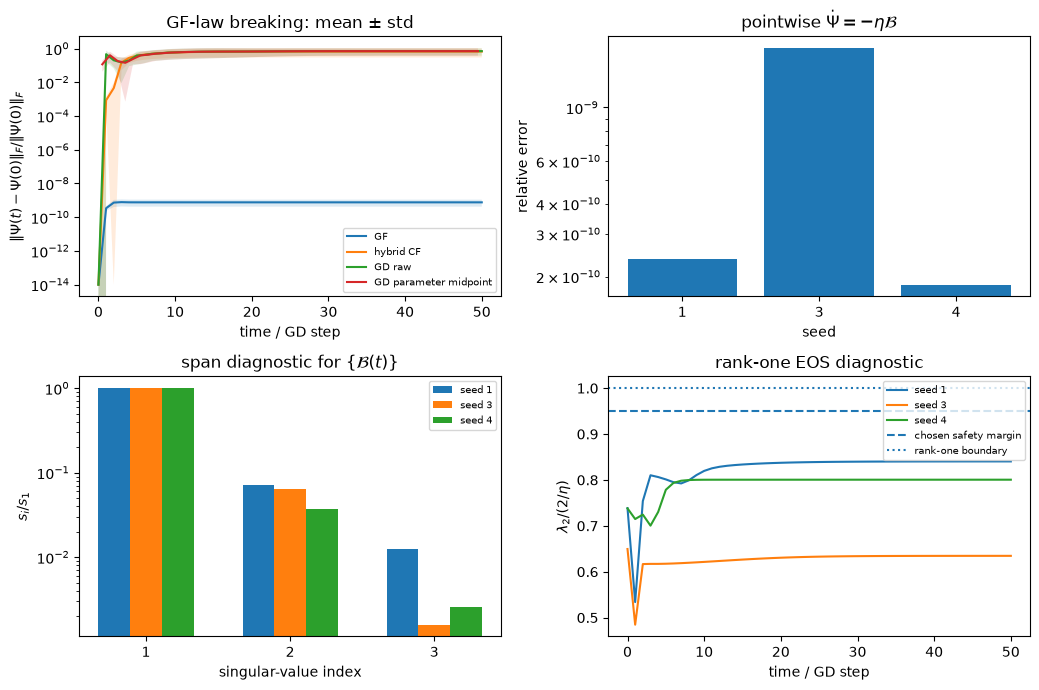

In [6]:
MF_RUNS = []
mf_rows = []

for seed in SEEDS_MF:
    model, theta0, eta, setup = setup_mf(seed)
    critical = 2.0 / eta

    t_gf, gf = integrate_gf(
        model, theta0, eta, T_MF, dt=0.02, output_dt=1.0
    )
    t_cf, cf = integrate_hybrid_cf(
        model, theta0, eta, T_MF, dt=0.1, output_dt=1.0
    )
    gd = gradient_descent(model, theta0, eta, T_MF)

    gd_mid = adjacent_midpoint(gd)
    t_mid = midpoint_times(len(gd))

    psi_gf = np.asarray([sym2_coords(model["psi"](th)) for th in gf])
    psi_cf = np.asarray([sym2_coords(model["psi"](th)) for th in cf])
    psi_gd = np.asarray([sym2_coords(model["psi"](th)) for th in gd])
    psi_mid = np.asarray([sym2_coords(model["psi"](th)) for th in gd_mid])

    psi0 = psi_gf[0].copy()
    assert np.linalg.norm(psi0) > 1e-8

    # The discrete run must actually realize the experimental premise.
    S_gd = np.asarray([top_eig(model, th)[0] for th in gd])
    gd_reached_eos = bool(np.max(S_gd) >= critical)
    assert gd_reached_eos, (
        f"MF seed {seed}: GD never reached EOS "
        f"(max sharpness={S_gd.max():.6f}, threshold={critical:.6f})"
    )

    # Pointwise theorem check at the first GF EOS hit.
    t_hit, theta_hit = find_gf_eos_hit(model, theta0, eta)
    rec_hit = boundary_record(model, theta_hit, eta)

    assert rec_hit["sigma2"] > 0.0
    assert rec_hit["eigengap"] > 1e-6
    assert rec_hit["eigvals"][-2] / critical < MF_RANK1_MAX_RATIO

    Btil_hit, Bcal_hit = model["breaking_rank1"](
        theta_hit, rec_hit["q"], rec_hit["sigma2"]
    )
    psi_dot_hit = model["psi_dot"](theta_hit, rec_hit["v_cf"])
    theorem_error = relative_error(psi_dot_hit, -eta * Bcal_hit)

    # Measure the instantaneous surviving subspace in Sym(2) ~= R^3.
    b_hit = sym2_coords(Bcal_hit)
    assert np.linalg.norm(b_hit) > 1e-12

    survivor_basis = null_space(b_hit.reshape(1, -1))
    instantaneous_surviving = int(survivor_basis.shape[1])
    survivor_drifts = survivor_basis.T @ sym2_coords(psi_dot_hit)
    max_survivor_drift = (
        float(np.max(np.abs(survivor_drifts)))
        if instantaneous_surviving else 0.0
    )

    # Trajectory B(t) geometry, restricted to active rank-one sampled points.
    Bcoords = []
    drift_errors = []
    lambda2_ratios = []
    active_lambda2_ratios = []
    active_times = []

    for tt, th in zip(t_cf, cf):
        vals, _ = spectrum(model, th)
        ratio2 = vals[-2] / critical
        lambda2_ratios.append(ratio2)

        if abs(vals[-1] - critical) <= 2e-3 * max(1.0, critical):
            rec = boundary_record(model, th, eta)

            if rec["sigma2"] > 1e-10:
                _, Bcal = model["breaking_rank1"](
                    th, rec["q"], rec["sigma2"]
                )
                measured = model["psi_dot"](th, rec["v_cf"])

                Bcoords.append(sym2_coords(Bcal))
                drift_errors.append(
                    relative_error(measured, -eta * Bcal)
                )
                active_lambda2_ratios.append(ratio2)
                active_times.append(tt)

    Bcoords = np.asarray(Bcoords)
    drift_errors = np.asarray(drift_errors)
    lambda2_ratios = np.asarray(lambda2_ratios)
    active_lambda2_ratios = np.asarray(active_lambda2_ratios)

    assert len(Bcoords) > 0, f"MF seed {seed}: no active CF samples"
    assert np.max(active_lambda2_ratios) < MF_RANK1_MAX_RATIO, (
        f"MF seed {seed}: rank-one margin too small, "
        f"max lambda2/(2/eta)={active_lambda2_ratios.max():.4f}"
    )

    svals = np.linalg.svd(Bcoords, compute_uv=False)
    svals_rel = svals / max(svals[0], 1e-15)
    numerical_span_rank = int(np.sum(svals_rel > 1e-3))

    run = {
        "seed": seed, "model": model, "eta": eta, "critical": critical,
        "t_gf": t_gf, "gf": gf, "t_cf": t_cf, "cf": cf, "gd": gd,
        "t_mid": t_mid, "gd_mid": gd_mid,
        "psi_gf": psi_gf, "psi_cf": psi_cf,
        "psi_gd": psi_gd, "psi_mid": psi_mid, "psi0": psi0,
        "S_gd": S_gd, "gd_reached_eos": gd_reached_eos,
        "theorem_error": theorem_error,
        "Bcoords": Bcoords, "svals_rel": svals_rel,
        "numerical_span_rank": numerical_span_rank,
        "lambda2_ratios": lambda2_ratios,
        "active_lambda2_ratios": active_lambda2_ratios,
        "drift_errors": drift_errors,
        "t_hit": t_hit,
        "survivor_basis": survivor_basis,
        "survivor_drifts": survivor_drifts,
        "instantaneous_surviving": instantaneous_surviving,
        "max_survivor_drift": max_survivor_drift,
    }
    MF_RUNS.append(run)

    mf_rows.append({
        "seed": seed,
        "eta": eta,
        "GD reached EOS": gd_reached_eos,
        "EOS hit time (GF)": t_hit,
        "pointwise relative error": theorem_error,
        "max trajectory drift-identity error":
            float(drift_errors.max()),
        "max active lambda2/(2/eta)":
            float(active_lambda2_ratios.max()),
        "B span s2/s1":
            svals_rel[1] if len(svals_rel) > 1 else np.nan,
        "B span s3/s1":
            svals_rel[2] if len(svals_rel) > 2 else np.nan,
        "numerical span rank (tol=1e-3)": numerical_span_rank,
        "measured instantaneous surviving laws":
            instantaneous_surviving,
        "max |drift| in measured survivor basis":
            max_survivor_drift,
    })

mf_df = pd.DataFrame(mf_rows)
display(mf_df)

# Aggregate full-law displacement, normalized by the original Psi(0).
D_gf = np.asarray([
    law_displacement(r["psi_gf"], initial=r["psi0"])
    for r in MF_RUNS
])
D_cf = np.asarray([
    law_displacement(r["psi_cf"], initial=r["psi0"])
    for r in MF_RUNS
])
D_gd = np.asarray([
    law_displacement(r["psi_gd"], initial=r["psi0"])
    for r in MF_RUNS
])
D_mid = np.asarray([
    law_displacement(r["psi_mid"], initial=r["psi0"])
    for r in MF_RUNS
])

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.0))

ax = axes[0, 0]
for t_plot, curves, label in [
    (MF_RUNS[0]["t_gf"], D_gf, "GF"),
    (MF_RUNS[0]["t_cf"], D_cf, "hybrid CF"),
    (np.arange(len(MF_RUNS[0]["gd"])), D_gd, "GD raw"),
    (MF_RUNS[0]["t_mid"], D_mid, "GD parameter midpoint"),
]:
    mean, std = mean_std(curves)
    ax.plot(t_plot, np.maximum(mean, 1e-14), label=label)
    ax.fill_between(
        t_plot,
        np.maximum(mean - std, 1e-14),
        mean + std,
        alpha=0.15,
    )
ax.set_yscale("log")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$\|\Psi(t)-\Psi(0)\|_F/\|\Psi(0)\|_F$")
ax.set_title("GF-law breaking: mean ± std")
ax.legend(fontsize=7)

ax = axes[0, 1]
errs = np.asarray([r["theorem_error"] for r in MF_RUNS])
ax.bar(np.arange(len(SEEDS_MF)), errs)
ax.set_yscale("log")
ax.set_xticks(
    np.arange(len(SEEDS_MF)),
    [str(s) for s in SEEDS_MF],
)
ax.set_xlabel("seed")
ax.set_ylabel("relative error")
ax.set_title(r"pointwise $\dot\Psi=-\eta\mathcal{B}$")

ax = axes[1, 0]
width = 0.22
x = np.arange(1, 4)
for k, r in enumerate(MF_RUNS):
    ax.bar(
        x + (k - 1) * width,
        r["svals_rel"],
        width=width,
        label=f"seed {r['seed']}",
    )
ax.set_xticks(x)
ax.set_xlabel("singular-value index")
ax.set_ylabel(r"$s_i/s_1$")
ax.set_yscale("log")
ax.set_title(r"span diagnostic for $\{\mathcal{B}(t)\}$")
ax.legend(fontsize=7)

ax = axes[1, 1]
for r in MF_RUNS:
    ax.plot(
        r["t_cf"],
        r["lambda2_ratios"],
        label=f"seed {r['seed']}",
    )
ax.axhline(
    MF_RANK1_MAX_RATIO,
    ls="--",
    label="chosen safety margin",
)
ax.axhline(1.0, ls=":", label="rank-one boundary")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$\lambda_2/(2/\eta)$")
ax.set_title("rank-one EOS diagnostic")
ax.legend(fontsize=7)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "matrix_factorization_multiseed.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()



## 3. Two-layer ReLU — local fixed-gate theorem, three seeds

The explicit ReLU breaking matrix is only justified while the rank-one oscillation remains in one activation region. We therefore use three deterministic seeds chosen **only** to satisfy the assumptions at the first active EOS point: simple top eigenvalue, \(\sigma^2>0\), \(\lambda_2<2/\eta\), and the exact two-point gate-safety test

\[
|z_{ij}|>\sqrt{\sigma^2}\,|q_{v_j}^\top x_i|
\quad\text{for all }i,j.
\]

No trajectory-level CF--GD agreement is used in selecting these seeds.


,seed,eta,EOS hit time (GF),gate margin min |z|/|delta z|,lambda2/(2/eta),pointwise relative error,max |drift| in basis of b^perp,instantaneous surviving laws
0,5,2.220924,4.980800,2.066037,0.585111,1.279015e-10,8.164003e-12,2
1,7,0.693422,2.940603,1.539090,0.494887,2.204689e-10,1.238331e-11,2
2,57,2.990917,5.853904,2.797368,0.661016,1.541295e-09,1.634638e-12,2


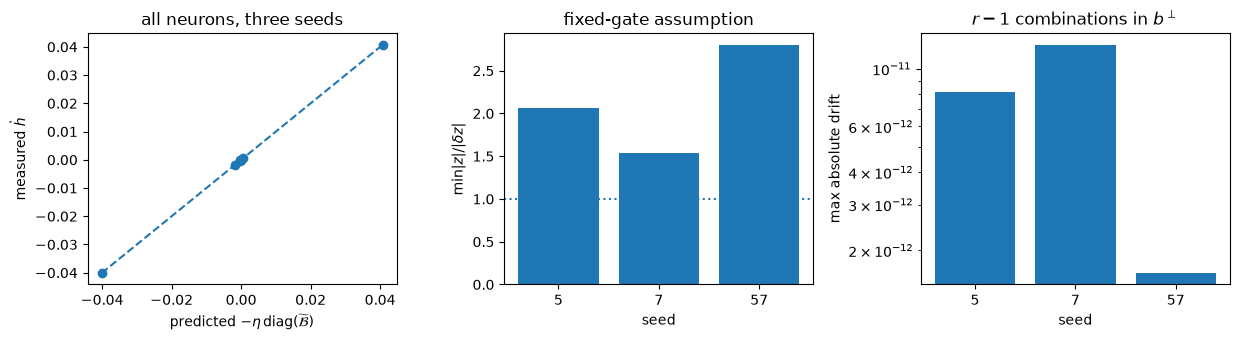

In [7]:

RELU_LOCAL_RUNS = []
relu_local_rows = []

all_measured = []
all_predicted = []

for seed in SEEDS_RELU_LOCAL:
    model, theta0, eta, setup = setup_relu(seed)
    critical = 2.0 / eta

    t_hit, theta_hit = find_gf_eos_hit(model, theta0, eta, max_time=60.0)
    rec = boundary_record(model, theta_hit, eta)

    gate = model["gate_safety_rank1"](theta_hit, rec["q"], rec["sigma2"])

    assert rec["sigma2"] > 0.0, f"seed {seed}: EOS constraint not active"
    assert rec["eigengap"] > 1e-4, f"seed {seed}: top eigenvalue not simple"
    assert rec["eigvals"][-2] < critical, f"seed {seed}: rank-one assumption fails"
    assert gate["safe"], f"seed {seed}: fixed-gate assumption fails"

    Btil = model["breaking_rank1"](theta_hit, rec["q"], rec["sigma2"])
    hdot_measured = model["hdot"](theta_hit, rec["v_cf"])
    hdot_predicted = -eta * np.diag(Btil)
    theorem_error = relative_error(hdot_measured, hdot_predicted)

    b = np.diag(Btil).copy()
    assert np.linalg.norm(b) > 1e-12

    # At a single realized nonzero covariance, b is one functional in R^r.
    # Its orthogonal complement has dimension r-1.
    null = null_space(b.reshape(1, -1))
    combo_drift = null.T @ hdot_measured

    RELU_LOCAL_RUNS.append({
        "seed": seed, "model": model, "eta": eta, "critical": critical,
        "theta_hit": theta_hit, "t_hit": t_hit, "rec": rec, "gate": gate,
        "Btil": Btil, "hdot_measured": hdot_measured,
        "hdot_predicted": hdot_predicted, "theorem_error": theorem_error,
        "combo_drift": combo_drift,
    })

    relu_local_rows.append({
        "seed": seed,
        "eta": eta,
        "EOS hit time (GF)": t_hit,
        "gate margin min |z|/|delta z|": gate["ratio"],
        "lambda2/(2/eta)": rec["eigvals"][-2] / critical,
        "pointwise relative error": theorem_error,
        "max |drift| in basis of b^perp": np.max(np.abs(combo_drift)),
        "instantaneous surviving laws": int(null.shape[1]),
    })

    all_measured.extend(hdot_measured.tolist())
    all_predicted.extend(hdot_predicted.tolist())

relu_local_df = pd.DataFrame(relu_local_rows)
display(relu_local_df)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.5))

ax = axes[0]
all_measured = np.asarray(all_measured)
all_predicted = np.asarray(all_predicted)
ax.scatter(all_predicted, all_measured)
lo = min(all_predicted.min(), all_measured.min())
hi = max(all_predicted.max(), all_measured.max())
ax.plot([lo, hi], [lo, hi], "--")
ax.set_xlabel(r"predicted $-\eta\,\mathrm{diag}(\widetilde{\mathcal{B}})$")
ax.set_ylabel(r"measured $\dot h$")
ax.set_title("all neurons, three seeds")

ax = axes[1]
ratios = [r["gate"]["ratio"] for r in RELU_LOCAL_RUNS]
ax.bar(np.arange(3), ratios)
ax.axhline(1.0, ls=":")
ax.set_xticks(np.arange(3), [str(s) for s in SEEDS_RELU_LOCAL])
ax.set_xlabel("seed")
ax.set_ylabel(r"$\min |z|/|\delta z|$")
ax.set_title("fixed-gate assumption")

ax = axes[2]
max_null = [np.max(np.abs(r["combo_drift"])) for r in RELU_LOCAL_RUNS]
ax.bar(np.arange(3), max_null)
ax.set_yscale("log")
ax.set_xticks(np.arange(3), [str(s) for s in SEEDS_RELU_LOCAL])
ax.set_xlabel("seed")
ax.set_ylabel("max absolute drift")
ax.set_title(r"$r-1$ combinations in $b^\perp$")

fig.tight_layout()
fig.savefig(RESULTS_DIR / "relu_local_theorem_multiseed.png", dpi=180, bbox_inches="tight")
plt.show()


## 4. ReLU trajectory stress test across gate changes — three seeds

We use three independent seeds, start below EOS, and compare GF,
raw GD, the adjacent-iterate **parameter midpoint**, the corrected hybrid CF,
and the `restore=5` stabilization as an ablation.

The ReLU GF reference is integrated with adaptive DOP853 at
\(10^{-10}\) relative and \(10^{-12}\) absolute tolerance; this removes the
\(10^{-5}\)-scale conservation floor produced by fixed-step RK4 across
activation kinks. Once the rank-one gate-safety ratio drops below one, the
explicit fixed-gate \(\widetilde{\mathcal B}_{\rm ReLU}\) theorem is no
longer certified.  We continue the piecewise-Hessian CF only as an empirical
stress test, and the output table explicitly flags such post-gate results as
uncertified.


,seed,eta,GD EOS step,first sampled CF gate failure time,CF endpoint fixed-gate certified?,fraction GD steps with gate changes,max lambda2/(2/eta),GF absolute law-drift floor (adaptive DOP853),post-EOS RMSE: hybrid CF vs GD midpoint,post-EOS RMSE: restore=5 vs GD midpoint,final CF law displacement (empirical if uncertified)
0,0,0.562825,4,3.0,False,0.8875,0.608702,1.917708e-14,0.097797,0.097315,0.386182
1,1,1.617986,3,2.0,False,0.8250,0.915861,1.034661e-14,0.050437,0.051655,2.477121
2,2,1.185711,4,3.0,False,0.9750,0.883670,1.362231e-11,0.352791,0.359524,0.461659


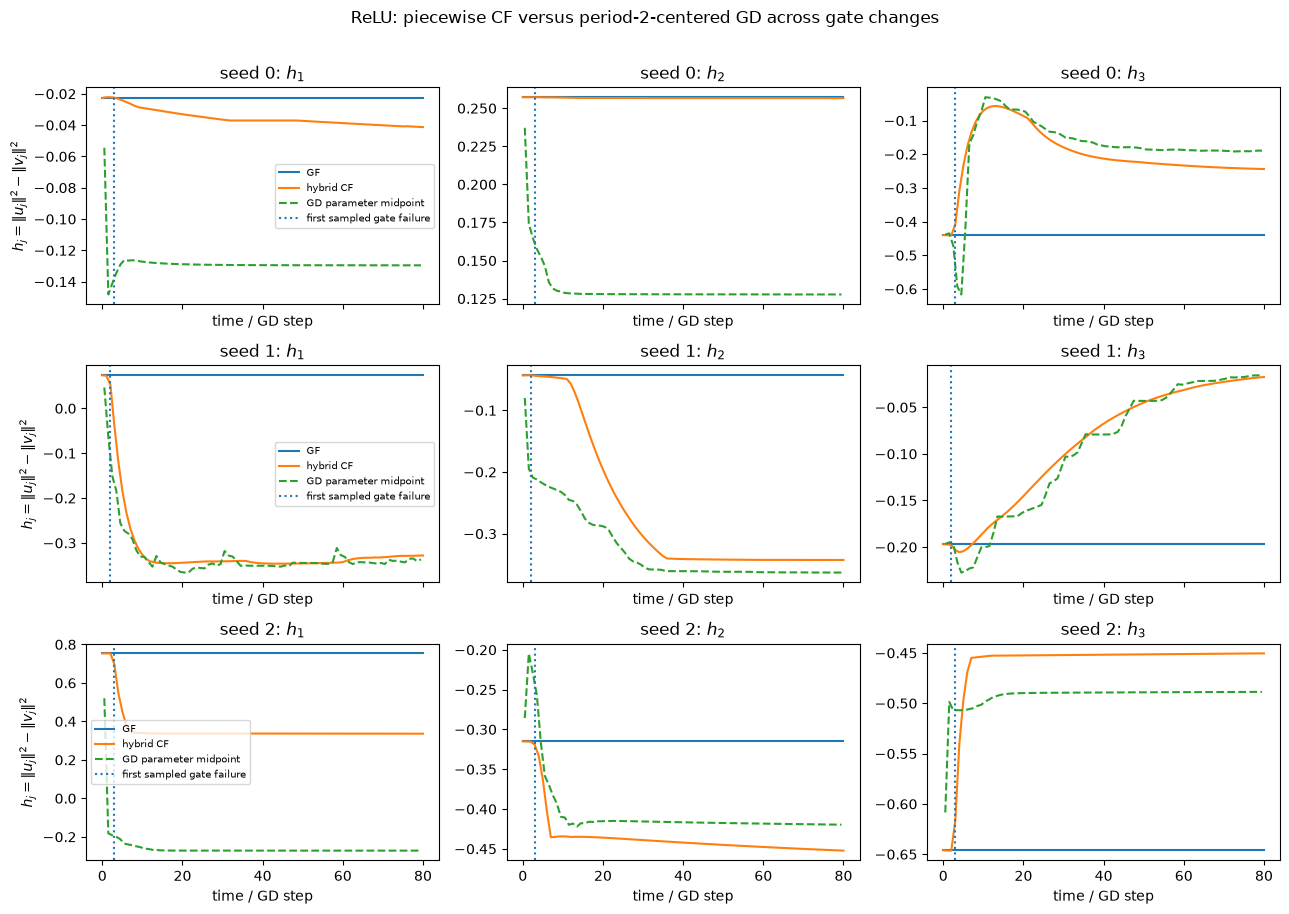

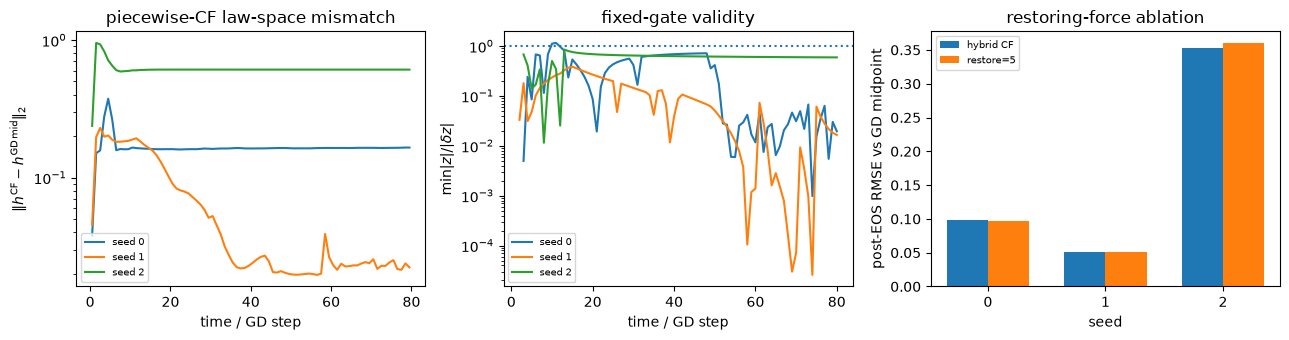

In [8]:
# Historical restoring heuristic, used only as an ablation.
def restore_record(model, theta, eta, restore=5.0):
    S, q, vals = top_eig(model, theta)
    g = np.asarray(model["grad"](theta), dtype=np.float64)
    gS = sharpness_grad(model, theta, q=q)

    critical = 2.0 / eta
    dS_gf = float((-eta * g) @ gS)
    denom = float(gS @ gS)
    sigma2 = 0.0

    if S >= critical and denom > 1e-18:
        target_dS = min(dS_gf, -restore * (S - critical))
        needed = dS_gf - target_dS

        if needed > 0.0:
            sigma2 = 2.0 * needed / (eta * denom)

    v = -eta * (
        g + 0.5 * sigma2 * gS
    ) if sigma2 > 0.0 else -eta * g

    return {
        "S": S, "q": q, "eigvals": vals, "sigma2": sigma2,
        "dS_gf": dS_gf, "v_cf": v,
    }


def integrate_restore_cf(model, theta0, eta, t_end, restore=5.0,
                         dt=0.1, output_dt=1.0):
    theta = np.asarray(theta0, dtype=np.float64).copy()
    times = np.arange(0.0, t_end + 0.5 * output_dt, output_dt)
    traj = [theta.copy()]

    for a, b in zip(times[:-1], times[1:]):
        width = float(b - a)
        n_sub = max(1, int(np.ceil(width / dt)))
        h = width / n_sub

        field = lambda th: restore_record(
            model, th, eta, restore=restore
        )["v_cf"]

        for _ in range(n_sub):
            theta = midpoint_step(theta, h, field)

        traj.append(theta.copy())

    return times, np.asarray(traj)



RELU_TRAJ_RUNS = []
relu_traj_rows = []

for seed in SEEDS_RELU_TRAJ:
    model, theta0, eta, setup = setup_relu(seed)
    critical = 2.0 / eta

    # High-accuracy GF reference across ReLU kinks.
    t_gf, gf = integrate_gf_adaptive(
        model, theta0, eta, T_RELU,
        output_dt=1.0,
        rtol=RELU_GF_RTOL,
        atol=RELU_GF_ATOL,
        max_step=0.05,
    )

    # Piecewise-Hessian hybrid CF; after a gate-safety failure this is empirical.
    t_cf, cf = integrate_hybrid_cf(
        model, theta0, eta, T_RELU,
        dt=0.1, output_dt=1.0,
    )

    t_restore, cf_restore = integrate_restore_cf(
        model, theta0, eta, T_RELU,
        restore=5.0, dt=0.1, output_dt=1.0,
    )

    gd = gradient_descent(model, theta0, eta, T_RELU)

    # Exact period-2 center in parameter space.
    gd_mid = adjacent_midpoint(gd)
    t_mid = midpoint_times(len(gd))

    h_gf = np.asarray([model["hvec"](th) for th in gf])
    h_cf = np.asarray([model["hvec"](th) for th in cf])
    h_restore = np.asarray([model["hvec"](th) for th in cf_restore])
    h_gd = np.asarray([model["hvec"](th) for th in gd])
    h_mid = np.asarray([model["hvec"](th) for th in gd_mid])

    h0 = h_gf[0].copy()
    assert np.linalg.norm(h0) > 1e-8

    # Interpolate the continuous trajectories to midpoint times for fair errors.
    h_cf_mid = interpolate_vector_values(t_mid, t_cf, h_cf)
    h_restore_mid = interpolate_vector_values(
        t_mid, t_restore, h_restore
    )

    # Sharpness / EOS diagnostics.
    S_gd = np.asarray([top_eig(model, th)[0] for th in gd])
    S_cf = np.asarray([top_eig(model, th)[0] for th in cf])
    S_restore = np.asarray([
        top_eig(model, th)[0] for th in cf_restore
    ])

    eos_gd_step = first_index(S_gd >= critical)

    # Gate safety of the rank-one two-point oscillation along hybrid CF.
    gate_ratio = np.full(len(cf), np.nan)
    gate_safe = np.ones(len(cf), dtype=bool)
    sigma2 = np.zeros(len(cf))
    lambda2_ratio = np.zeros(len(cf))

    for k, th in enumerate(cf):
        vals, _ = spectrum(model, th)
        lambda2_ratio[k] = vals[-2] / critical

        if abs(vals[-1] - critical) <= 2e-3 * max(1.0, critical):
            rec = boundary_record(model, th, eta)
            sigma2[k] = rec["sigma2"]

            if rec["sigma2"] > 1e-10:
                gate = model["gate_safety_rank1"](
                    th, rec["q"], rec["sigma2"]
                )
                gate_ratio[k] = gate["ratio"]
                gate_safe[k] = gate["safe"]

    first_gate_failure = first_index(
        np.isfinite(gate_ratio) & (gate_ratio <= 1.0)
    )
    gate_failure_time = (
        float(t_cf[first_gate_failure])
        if first_gate_failure is not None
        else np.nan
    )
    cf_endpoint_certified = first_gate_failure is None

    # Actual discrete GD gate changes.
    gd_masks = np.asarray([
        model["forward"](th)[1] > 0.0
        for th in gd
    ])
    gd_gate_changes = np.sum(
        gd_masks[1:] != gd_masks[:-1],
        axis=(1, 2),
    )

    # Post-EOS comparison against the period-2 parameter center.
    if eos_gd_step is None:
        post_mask_mid = np.ones(len(t_mid), dtype=bool)
    else:
        post_mask_mid = t_mid >= float(eos_gd_step)

    err_cf_mid = np.linalg.norm(
        h_cf_mid - h_mid,
        axis=1,
    )
    err_restore_mid = np.linalg.norm(
        h_restore_mid - h_mid,
        axis=1,
    )

    post_rmse_cf = np.sqrt(np.mean(
        (h_cf_mid[post_mask_mid] - h_mid[post_mask_mid]) ** 2
    ))
    post_rmse_restore = np.sqrt(np.mean(
        (h_restore_mid[post_mask_mid] - h_mid[post_mask_mid]) ** 2
    ))

    gf_floor = np.max(np.linalg.norm(h_gf - h0[None, :], axis=1))

    run = {
        "seed": seed, "model": model, "eta": eta, "critical": critical,
        "t_gf": t_gf, "gf": gf, "t_cf": t_cf, "cf": cf,
        "t_restore": t_restore, "cf_restore": cf_restore,
        "gd": gd, "t_mid": t_mid, "gd_mid": gd_mid,
        "h_gf": h_gf, "h_cf": h_cf, "h_restore": h_restore,
        "h_gd": h_gd, "h_mid": h_mid, "h0": h0,
        "h_cf_mid": h_cf_mid, "h_restore_mid": h_restore_mid,
        "S_gd": S_gd, "S_cf": S_cf, "S_restore": S_restore,
        "gate_ratio": gate_ratio, "gate_safe": gate_safe,
        "sigma2": sigma2, "lambda2_ratio": lambda2_ratio,
        "first_gate_failure": first_gate_failure,
        "gate_failure_time": gate_failure_time,
        "cf_endpoint_certified": cf_endpoint_certified,
        "gd_gate_changes": gd_gate_changes,
        "eos_gd_step": eos_gd_step,
        "err_cf_mid": err_cf_mid,
        "err_restore_mid": err_restore_mid,
        "post_rmse_cf": post_rmse_cf,
        "post_rmse_restore": post_rmse_restore,
        "gf_floor": gf_floor,
    }
    RELU_TRAJ_RUNS.append(run)

    relu_traj_rows.append({
        "seed": seed,
        "eta": eta,
        "GD EOS step": eos_gd_step,
        "first sampled CF gate failure time": gate_failure_time,
        "CF endpoint fixed-gate certified?": cf_endpoint_certified,
        "fraction GD steps with gate changes":
            np.mean(gd_gate_changes > 0),
        "max lambda2/(2/eta)": np.max(lambda2_ratio),
        "GF absolute law-drift floor (adaptive DOP853)": gf_floor,
        "post-EOS RMSE: hybrid CF vs GD midpoint": post_rmse_cf,
        "post-EOS RMSE: restore=5 vs GD midpoint": post_rmse_restore,
        "final CF law displacement (empirical if uncertified)":
            law_displacement(h_cf, initial=h0)[-1],
    })

relu_traj_df = pd.DataFrame(relu_traj_rows)
display(relu_traj_df)

# ------------------------------------------------------------
# Individual h_j trajectories: one row per seed.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(RELU_TRAJ_RUNS), 3,
    figsize=(13.0, 3.0 * len(RELU_TRAJ_RUNS)),
    sharex=True,
)

for row, run in enumerate(RELU_TRAJ_RUNS):
    for j in range(3):
        ax = axes[row, j]

        ax.plot(run["t_gf"], run["h_gf"][:, j], label="GF")
        ax.plot(run["t_cf"], run["h_cf"][:, j], label="hybrid CF")
        ax.plot(
            run["t_mid"], run["h_mid"][:, j],
            "--", label="GD parameter midpoint",
        )

        if run["first_gate_failure"] is not None:
            ax.axvline(
                run["gate_failure_time"],
                ls=":",
                label="first sampled gate failure" if j == 0 else None,
            )

        ax.set_title(rf"seed {run['seed']}: $h_{j+1}$")
        ax.set_xlabel("time / GD step")

        if j == 0:
            ax.set_ylabel(r"$h_j=\|u_j\|^2-\|v_j\|^2$")
            ax.legend(fontsize=7)

fig.suptitle(
    "ReLU: piecewise CF versus period-2-centered GD across gate changes",
    y=1.01,
)
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "relu_trajectory_multiseed.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Cross-seed stress-test diagnostics.
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.5))

ax = axes[0]
for run in RELU_TRAJ_RUNS:
    ax.plot(
        run["t_mid"], run["err_cf_mid"],
        label=f"seed {run['seed']}",
    )
ax.set_yscale("log")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$\|h^{\rm CF}-h^{\rm GD\,mid}\|_2$")
ax.set_title("piecewise-CF law-space mismatch")
ax.legend(fontsize=7)

ax = axes[1]
for run in RELU_TRAJ_RUNS:
    ax.plot(
        run["t_cf"], run["gate_ratio"],
        label=f"seed {run['seed']}",
    )
ax.axhline(1.0, ls=":")
ax.set_yscale("log")
ax.set_xlabel("time / GD step")
ax.set_ylabel(r"$\min |z|/|\delta z|$")
ax.set_title("fixed-gate validity")
ax.legend(fontsize=7)

ax = axes[2]
x = np.arange(len(RELU_TRAJ_RUNS))
width = 0.35
ax.bar(
    x - width / 2,
    [r["post_rmse_cf"] for r in RELU_TRAJ_RUNS],
    width=width,
    label="hybrid CF",
)
ax.bar(
    x + width / 2,
    [r["post_rmse_restore"] for r in RELU_TRAJ_RUNS],
    width=width,
    label="restore=5",
)
ax.set_xticks(x, [str(r["seed"]) for r in RELU_TRAJ_RUNS])
ax.set_xlabel("seed")
ax.set_ylabel("post-EOS RMSE vs GD midpoint")
ax.set_title("restoring-force ablation")
ax.legend(fontsize=7)

fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "relu_gate_crossing_stress_test.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


## Paper-motivation summary (not included in paper results)

The figure tracks the known GF conservation-law vector under GF, GD,
and hybrid CF for all three architectures, with mean \(\pm\) one standard
deviation over three seeds.

All matrix-factorization seeds included here satisfy the intended settings:
discrete GD reaches EOS and the active hybrid-CF trajectory stays below the
chosen rank-one safety margin.  For ReLU, the full CF curve after the first
gate-safety failure is explicitly an empirical piecewise-Hessian
continuation; only the separate fixed-gate experiment validates the explicit
ReLU breaking-matrix formula.


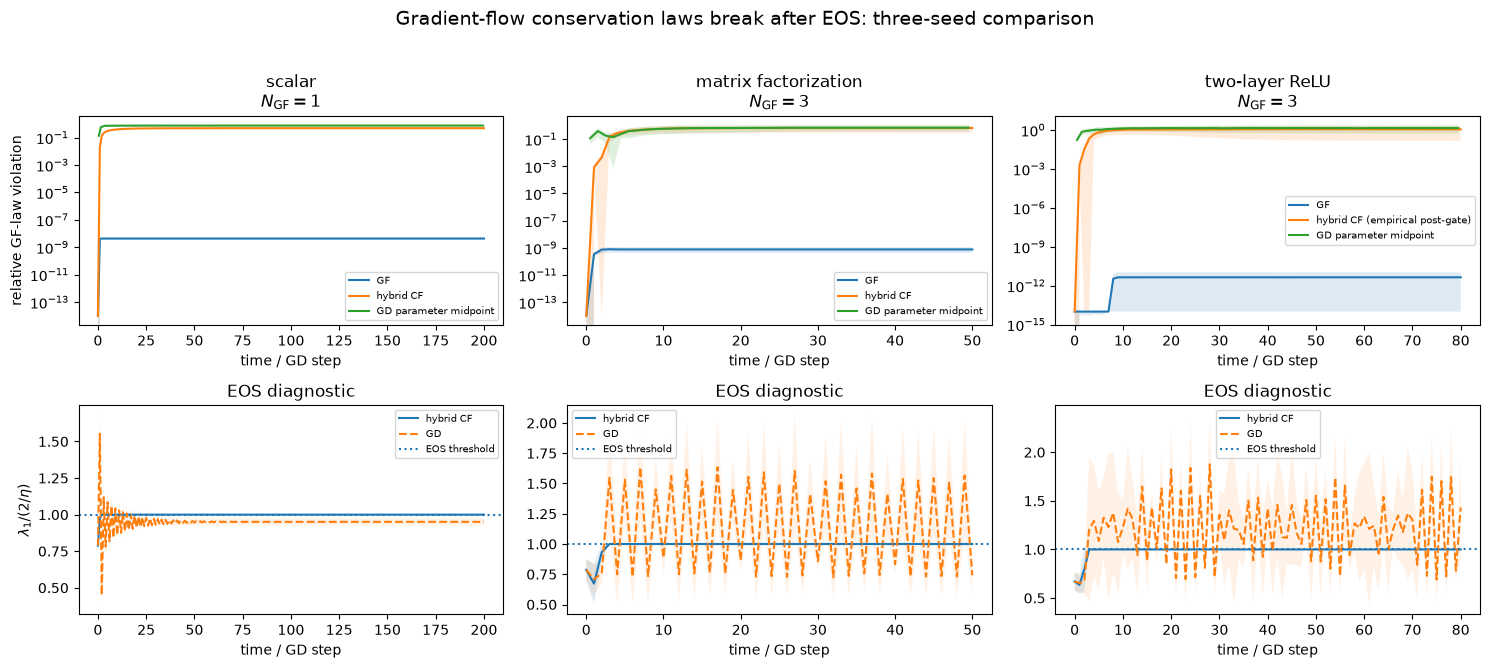

,architecture,seed,N_GF,GF max absolute law drift,GD reached EOS,final centered-GD law displacement,final CF law displacement,CF endpoint certified by stated local theorem?,first gate-failure time (ReLU only)
0,scalar,0,1,8.535730e-09,True,0.774458,0.418809,True,NaN
1,scalar,1,1,4.856107e-09,True,0.699571,0.519696,True,NaN
2,scalar,2,1,5.235985e-09,True,0.776812,0.515318,True,NaN
3,matrix factorization,1,3,4.009087e-10,True,0.968192,0.959925,True,NaN
4,matrix factorization,3,3,1.149197e-09,True,0.888570,0.885025,True,NaN
5,matrix factorization,4,3,2.548075e-09,True,0.242652,0.145038,True,NaN
6,two-layer ReLU,0,3,1.917708e-14,True,0.591493,0.386182,False,3.0
7,two-layer ReLU,1,3,1.034661e-14,True,2.565117,2.477121,False,2.0
8,two-layer ReLU,2,3,1.362231e-11,True,1.001013,0.461659,False,3.0


Saved: /Users/nelbo/Documents/PhD_work/code/CF_conserved_quantities/notebooks/cf_multiseed_results_fixed/summary.csv


In [9]:
def aggregate_architecture_runs(
    runs,
    key_gf,
    key_cf,
    key_gd_center,
    key_initial,
):
    Dgf = np.asarray([
        law_displacement(r[key_gf], initial=r[key_initial])
        for r in runs
    ])
    Dcf = np.asarray([
        law_displacement(r[key_cf], initial=r[key_initial])
        for r in runs
    ])
    Dgd = np.asarray([
        law_displacement(r[key_gd_center], initial=r[key_initial])
        for r in runs
    ])
    return Dgf, Dcf, Dgd


scalar_agg = aggregate_architecture_runs(
    SCALAR_RUNS, "h_gf", "h_cf", "h_mid", "h0"
)
mf_agg = aggregate_architecture_runs(
    MF_RUNS, "psi_gf", "psi_cf", "psi_mid", "psi0"
)
relu_agg = aggregate_architecture_runs(
    RELU_TRAJ_RUNS, "h_gf", "h_cf", "h_mid", "h0"
)

architectures = [
    ("scalar", SCALAR_RUNS, scalar_agg, 1),
    ("matrix factorization", MF_RUNS, mf_agg, 3),
    ("two-layer ReLU", RELU_TRAJ_RUNS, relu_agg, 3),
]

fig, axes = plt.subplots(2, 3, figsize=(15.0, 6.5))

for col, (name, runs, agg, n_gf) in enumerate(architectures):
    Dgf, Dcf, Dgd = agg

    # --------------------------------------------------------
    # Top: GF-law violation.
    # --------------------------------------------------------
    ax = axes[0, col]

    mgf, sgf = mean_std(Dgf)
    mcf, scf = mean_std(Dcf)
    mgd, sgd = mean_std(Dgd)

    ax.plot(
        runs[0]["t_gf"],
        np.maximum(mgf, 1e-14),
        label="GF",
    )
    ax.fill_between(
        runs[0]["t_gf"],
        np.maximum(mgf - sgf, 1e-14),
        mgf + sgf,
        alpha=0.15,
    )

    cf_label = (
        "hybrid CF (empirical post-gate)"
        if name == "two-layer ReLU"
        else "hybrid CF"
    )
    ax.plot(
        runs[0]["t_cf"],
        np.maximum(mcf, 1e-14),
        label=cf_label,
    )
    ax.fill_between(
        runs[0]["t_cf"],
        np.maximum(mcf - scf, 1e-14),
        mcf + scf,
        alpha=0.15,
    )

    ax.plot(
        runs[0]["t_mid"],
        np.maximum(mgd, 1e-14),
        label="GD parameter midpoint",
    )
    ax.fill_between(
        runs[0]["t_mid"],
        np.maximum(mgd - sgd, 1e-14),
        mgd + sgd,
        alpha=0.15,
    )

    ax.set_yscale("log")
    ax.set_xlabel("time / GD step")
    ax.set_title(name + "\n" + rf"$N_{{\rm GF}}={n_gf}$")

    if col == 0:
        ax.set_ylabel("relative GF-law violation")

    ax.legend(fontsize=7)

    # --------------------------------------------------------
    # Bottom: EOS diagnostic from actual GD and hybrid CF.
    # --------------------------------------------------------
    ax = axes[1, col]

    gd_ratios = []
    cf_ratios = []

    for run in runs:
        critical = run["critical"]

        if name == "scalar":
            Sgd = np.asarray([
                top_eig(run["model"], th)[0]
                for th in run["gd"]
            ])
            Scf = run["diag_cf"]["lambda1"]
        elif name == "matrix factorization":
            Sgd = run["S_gd"]
            Scf = np.asarray([
                top_eig(run["model"], th)[0]
                for th in run["cf"]
            ])
        else:
            Sgd = run["S_gd"]
            Scf = run["S_cf"]

        gd_ratios.append(Sgd / critical)
        cf_ratios.append(Scf / critical)

    gd_ratios = np.asarray(gd_ratios)
    cf_ratios = np.asarray(cf_ratios)

    mgd_S, sgd_S = mean_std(gd_ratios)
    mcf_S, scf_S = mean_std(cf_ratios)

    t_integer = runs[0]["t_cf"]

    ax.plot(t_integer, mcf_S, label="hybrid CF")
    ax.fill_between(
        t_integer,
        mcf_S - scf_S,
        mcf_S + scf_S,
        alpha=0.15,
    )

    ax.plot(t_integer, mgd_S, "--", label="GD")
    ax.fill_between(
        t_integer,
        mgd_S - sgd_S,
        mgd_S + sgd_S,
        alpha=0.10,
    )

    ax.axhline(1.0, ls=":", label="EOS threshold")
    ax.set_xlabel("time / GD step")

    if col == 0:
        ax.set_ylabel(r"$\lambda_1/(2/\eta)$")

    ax.set_title("EOS diagnostic")
    ax.legend(fontsize=7)

fig.suptitle(
    "Gradient-flow conservation laws break after EOS: three-seed comparison",
    y=1.02,
    fontsize=14,
)
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "paper_motivation_multiseed.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


# ------------------------------------------------------------
# Compact numerical summary
# ------------------------------------------------------------

summary_rows = []

for name, runs, _, n_gf in architectures:
    for run in runs:
        critical = run["critical"]

        if name == "scalar":
            gf_drift = np.max(np.abs(
                run["h_gf"] - run["h0"]
            ))
            gd_law = run["h_mid"]
            cf_law = run["h_cf"]
            initial_law = run["h0"]
            gd_S = np.asarray([
                top_eig(run["model"], th)[0]
                for th in run["gd"]
            ])
            cf_certified = True
            gate_failure_time = np.nan

        elif name == "matrix factorization":
            gf_drift = np.max(np.linalg.norm(
                run["psi_gf"] - run["psi0"][None, :],
                axis=1,
            ))
            gd_law = run["psi_mid"]
            cf_law = run["psi_cf"]
            initial_law = run["psi0"]
            gd_S = run["S_gd"]
            cf_certified = True
            gate_failure_time = np.nan

        else:
            gf_drift = np.max(np.linalg.norm(
                run["h_gf"] - run["h0"][None, :],
                axis=1,
            ))
            gd_law = run["h_mid"]
            cf_law = run["h_cf"]
            initial_law = run["h0"]
            gd_S = run["S_gd"]
            cf_certified = run["cf_endpoint_certified"]
            gate_failure_time = run["gate_failure_time"]

        summary_rows.append({
            "architecture": name,
            "seed": run["seed"],
            "N_GF": n_gf,
            "GF max absolute law drift": gf_drift,
            "GD reached EOS": bool(np.max(gd_S) >= 0.99 * critical),
            "final centered-GD law displacement":
                law_displacement(
                    gd_law,
                    initial=initial_law,
                )[-1],
            "final CF law displacement":
                law_displacement(
                    cf_law,
                    initial=initial_law,
                )[-1],
            "CF endpoint certified by stated local theorem?":
                cf_certified,
            "first gate-failure time (ReLU only)":
                gate_failure_time,
        })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

summary_df.to_csv(
    RESULTS_DIR / "summary.csv",
    index=False,
)
print("Saved:", RESULTS_DIR / "summary.csv")


## Notes of caution when interpreting results 

- **Scalar:** the pointwise drift identity and sign prediction are theorem
  checks.  The terminal equality between \(|h_{\rm CF}|\) and the stability
  bound is reported as an empirical saturation result over three seeds.
- **Matrix factorization:** \(\dot\Psi=-\eta\mathcal B\) is checked pointwise
  and along active rank-one CF samples.  Every included seed is asserted to
  reach EOS under discrete GD and to satisfy the chosen
  \(\lambda_2/(2/\eta)<0.95\) safety margin.  The instantaneous survivor count
  is measured from the null space of the realized breaking functional.  The
  singular values of stacked \(\mathcal B(t)\) remain empirical span
  diagnostics, not a proof of generic maximal rank.
- **ReLU fixed-gate:** the explicit diagonal breaking-matrix identity is only
  claimed at points passing the gate-safety test.
- **ReLU across kinks:** Agreement or
  disagreement between piecewise CF and period-2-centered GD is reported
  seed-by-seed.  Once gate safety fails, the CF continuation is explicitly
  marked uncertified by the fixed-gate theorem.  The `restore=5` curve is a
  historical/numerical ablation only.


